In [41]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 18장 강화 학습

## 18.3 OpenAI Gym

In [42]:
import gymnasium as gym

env = gym.make('CartPole-v1', render_mode='rgb_array')

In [43]:
list(gym.envs.registry.keys())[:10]

['CartPole-v0',
 'CartPole-v1',
 'MountainCar-v0',
 'MountainCarContinuous-v0',
 'Pendulum-v1',
 'Acrobot-v1',
 'phys2d/CartPole-v0',
 'phys2d/CartPole-v1',
 'phys2d/Pendulum-v0',
 'LunarLander-v3']

In [44]:
obs, info = env.reset(seed=42)

In [45]:
obs

array([ 0.0273956 , -0.00611216,  0.03585979,  0.0197368 ], dtype=float32)

In [46]:
info

{}

In [47]:
img = env.render()
img.shape

(400, 600, 3)

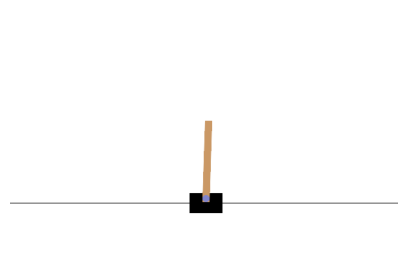

In [48]:
def plot_env(env, figsize=(5, 4)):
    plt.figure(figsize=figsize)
    img = env.render()
    plt.imshow(img)
    plt.axis('off')
    return img

plot_env(env)
plt.show()

In [49]:
env.action_space

Discrete(2)

In [50]:
action = 1
obs, reward, done, truncated, info = env.step(action)

obs, reward, done, truncated, info

(array([ 0.02727336,  0.18847767,  0.03625453, -0.26141977], dtype=float32),
 1.0,
 False,
 False,
 {})

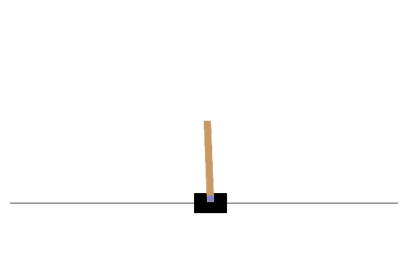

In [51]:
for _ in range(5):
    env.step(action)

plot_env(env)
plt.show()

In [52]:
def basic_policy(obs):
    angle = obs[2]
    return 0 if angle < 0 else 1

totals = []
for episode in range(500):
    episode_rewards = 0
    obs, info = env.reset(seed=episode)
    for step in range(200):
        action = basic_policy(obs)
        obs, reward, done, truncated, info = env.step(action)
        episode_rewards += reward
        if done or truncated:
            break
    totals.append(episode_rewards)

In [53]:
np.mean(totals), np.std(totals), np.min(totals), np.max(totals)

(np.float64(41.698),
 np.float64(8.389445512070509),
 np.float64(24.0),
 np.float64(63.0))

In [54]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def show_one_episode(policy, n_max_steps=200, seed=42):
    frames = []
    rewards = [0]
    
    env = gym.make('CartPole-v1', render_mode='rgb_array')
    obs, info = env.reset(seed=seed)
    reward = 0
    for step in range(n_max_steps):
        frames.append(env.render())        
        action = policy(obs)
        obs, reward, done, truncated, info = env.step(action)
        rewards.append(rewards[-1] + reward)
        if done or truncated:
            break
    env.close()
    
    fig = plt.figure()
    plt.axis('off')
    patch = (plt.text(2, 20, ''), plt.imshow(frames[0]))
    def update(idx, frames, rewards, patc):
        text, imshow = patch
        text.set_text(f'reward: {rewards[idx]}')
        imshow.set_data(frames[idx])
        return text, imshow

    anim = FuncAnimation(
        fig, update, fargs=(frames, rewards, patch),
        frames=len(frames), interval=40, blit=True)
    plt.close()
    return HTML(anim.to_jshtml())

show_one_episode(basic_policy)

## 18.4 신경망 정책

In [55]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(5, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

## 18.6 정책 그레이디언트

In [56]:
def play_one_step(env, obs, model, loss_fn):
    with tf.GradientTape() as tape:
        left_proba = model(obs[np.newaxis])
        action = (tf.random.uniform([1, 1]) > left_proba)
        y_target = tf.constant([[1.]]) - tf.cast(action, tf.float32)
        loss = tf.reduce_mean(loss_fn(y_target, left_proba))

    grads = tape.gradient(loss, model.trainable_variables)
    obs, reward, done, truncated, info = env.step(int(action[0, 0]))
    return obs, reward, done, truncated, grads

In [57]:
def play_multiple_episodes(env, n_episodes, n_max_steps, model, loss_fn):
    all_rewards = []
    all_grads = []
    for episode in range(n_episodes):
        current_rewards = []
        current_grads = []
        obs, info = env.reset()
        for step in range(n_max_steps):
            obs, reward, done, truncated, grads = play_one_step(env, obs, model, loss_fn)
            current_rewards.append(reward)
            current_grads.append(grads)
            if done or truncated:
                break

        all_rewards.append(current_rewards)
        all_grads.append(current_grads)
    
    return all_rewards, all_grads

In [58]:
def discount_rewards(rewards, discount_factor):
    discounted = np.array(rewards)
    for step in range(len(rewards) - 2, -1, -1):
        discounted[step] += discounted[step + 1] * discount_factor
    return discounted

def discount_and_normalize_rewards(all_rewards, discount_factor):
    all_discounted_rewards = [discount_rewards(rewards, discount_factor)
                              for rewards in all_rewards]
    flat_rewards = np.concatenate(all_discounted_rewards)
    reward_mean = np.mean(flat_rewards)
    reward_std = np.std(flat_rewards)
    return [(discounted_rewards - reward_mean) / reward_std
            for discounted_rewards in all_discounted_rewards]

In [59]:
discount_rewards([10, 0, -50], discount_factor=0.8)

array([-22, -40, -50])

In [60]:
discount_and_normalize_rewards([[10, 0, -50], [10, 20]],
                               discount_factor=0.8)

[array([-0.28435071, -0.86597718, -1.18910299]),
 array([1.26665318, 1.0727777 ])]

In [61]:
n_iterations = 150
n_episodes_per_update = 10
n_max_steps = 200
discount_factor = 0.9

optimizer = tf.keras.optimizers.Nadam(learning_rate=0.01)
loss_fn = tf.keras.losses.binary_crossentropy

In [62]:
tf.random.set_seed(42)

for iteration in range(n_iterations):
    all_rewards, all_grads = play_multiple_episodes(
        env, n_episodes_per_update, n_max_steps, model, loss_fn)
    all_final_rewards = discount_and_normalize_rewards(all_rewards, discount_factor)
    
    if (iteration + 1) % 10 == 0:
        total_rewards = sum(map(sum, all_rewards))
        print(f'Episodes: {iteration + 1}/{n_iterations}\t \
                Mean reward: {total_rewards / n_episodes_per_update:.1f}')

    all_mean_grads = []
    for var_index in range(len(model.trainable_variables)):
        mean_grads = tf.reduce_mean(
            [all_grads[episode][step][var_index] * final_reward
             for episode, final_rewards in enumerate(all_final_rewards)
             for step, final_reward in enumerate(final_rewards)],
            axis=0
        )
        all_mean_grads.append(mean_grads)
    optimizer.apply_gradients(zip(all_mean_grads, model.trainable_variables))

Episodes: 10/150	                 Mean reward: 22.4
Episodes: 20/150	                 Mean reward: 40.8
Episodes: 30/150	                 Mean reward: 30.2
Episodes: 40/150	                 Mean reward: 45.2
Episodes: 50/150	                 Mean reward: 51.3
Episodes: 60/150	                 Mean reward: 56.5
Episodes: 70/150	                 Mean reward: 72.6
Episodes: 80/150	                 Mean reward: 125.3
Episodes: 90/150	                 Mean reward: 157.6
Episodes: 100/150	                 Mean reward: 152.5
Episodes: 110/150	                 Mean reward: 179.3
Episodes: 120/150	                 Mean reward: 193.7
Episodes: 130/150	                 Mean reward: 189.6
Episodes: 140/150	                 Mean reward: 183.5
Episodes: 150/150	                 Mean reward: 198.2


In [63]:
np.random.seed(42)

def pg_policy(obs):
    left_proba = model.predict(obs[np.newaxis], verbose=0)[0, 0]
    return int(np.random.rand() > left_proba)

show_one_episode(pg_policy)

## 18.7 마르코프 결정 과정

In [64]:
transition_probabilities = [  # shape=(s, a, s')
    [[0.7, 0.3, 0.0], [1.0, 0.0, 0.0], [0.8, 0.2, 0.0]],
    [[0.0, 1.0, 0.0], None, [0.0, 0.0, 1.0]],
    [None, [0.8, 0.1, 0.1], None]
]

rewards = [  # shape=(s, a, s')
    [[+10, 0, 0], [0, 0, 0], [0, 0, 0]],
    [[0, 0, 0], [0, 0, 0], [0, 0, -50]],
    [[0, 0, 0], [+40, 0, 0], [0, 0, 0]]
]

possible_actions = [[0, 1, 2], [0, 2], [1]]

In [65]:
Q_values = np.full((3, 3), -np.inf)
for state, actions in enumerate(possible_actions):
    Q_values[state, actions] = 0.0

In [66]:
gamma = 0.9
history1 = []

for iteratio in range(50):
    history1.append(Q_values.copy())
    Q_prev = Q_values.copy()
    for s in range(3):
        for a in possible_actions[s]:
            Q_values[s, a] = np.sum([
                    transition_probabilities[s][a][next_s]
                    * (rewards[s][a][next_s] + gamma * Q_prev[next_s].max())
                for next_s in range(3)
            ])

Q_values

array([[18.91891892, 17.02702702, 13.62162162],
       [ 0.        ,        -inf, -4.87971488],
       [       -inf, 50.13365013,        -inf]])

In [67]:
np.argmax(Q_values, axis=1)

array([0, 0, 1])

In [68]:
gamma = 0.95

for iteration in range(50):
    Q_prev = Q_values.copy()
    for s in range(3):
        for a in possible_actions[s]:
            Q_values[s, a] = np.sum([
                    transition_probabilities[s][a][next_s]
                    * (rewards[s][a][next_s] + gamma * Q_prev[next_s].max())
                for next_s in range(3)
            ])

Q_values

array([[21.77572778, 20.68076527, 16.74407361],
       [ 0.99730695,        -inf,  1.05629796],
       [       -inf, 53.74997271,        -inf]])

In [69]:
np.argmax(Q_values, axis=1)

array([0, 2, 1])

## 18.9 Q-러닝

In [70]:
def step(state, action):
    probas = transition_probabilities[state][action]
    next_state = np.random.choice([0, 1, 2], p=probas)
    reward = rewards[state][action][next_state]
    return next_state, reward

In [71]:
def exploration_policy(state):
    return np.random.choice(possible_actions[state])

In [72]:
Q_values = np.full((3, 3), -np.inf)
for state, actions in enumerate(possible_actions):
    Q_values[state][actions] = 0

In [73]:
np.random.seed(42)

alpha0 = 0.05
decay = 0.005
gamma = 0.9
state = 0
history2 = []

for iteration in range(10_000):
    history2.append(Q_values.copy())
    action = exploration_policy(state)
    next_state, reward = step(state, action)
    next_value = Q_values[next_state].max()
    alpha = alpha0 / (1 + iteration * decay)
    Q_values[state][action] *= 1 - alpha
    Q_values[state][action] += alpha * (reward + gamma * next_value)
    state = next_state

Q_values

array([[18.77621289, 17.2238872 , 13.74543343],
       [ 0.        ,        -inf, -8.00485647],
       [       -inf, 49.40208921,        -inf]])

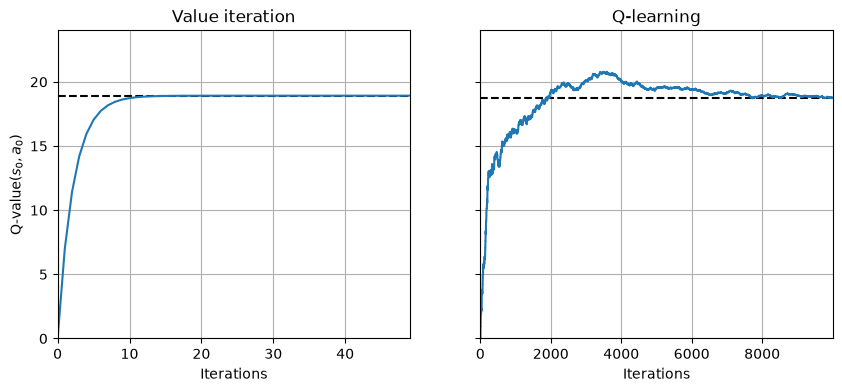

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].set_ylabel('Q-value($s_0, a_0$)')
axes[0].set_title('Value iteration')
axes[1].set_title('Q-learning')
for ax, history in zip(axes, [history1, history2]):
    length = len(history)
    history = np.array(history)
    ax.hlines(history[-1, 0, 0], 0, length - 1, color='black', linestyles='dashed')
    ax.plot(history[:, 0, 0])
    ax.grid()
    ax.axis([0, length - 1, 0, 24])
    ax.set_xlabel('Iterations')